# Análisis de sismicidad de Colombia con el catálogo del USGS

**Cuaderno reproducible · catálogo USGS 2000–2026 · completitud y relación de Gutenberg-Richter**

+++ {"no-pdf": true}

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/scr-ungrd/cuadernos-reproducibles-crc003/blob/main/sismicidad-colombia.ipynb) [![Abrir en Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/scr-ungrd/cuadernos-reproducibles-crc003/main?filepath=sismicidad-colombia.ipynb)

+++

---

## Stack

```text
Herramienta principal: Python 3.11 con pandas, numpy, scipy, matplotlib, folium y plotly
Datos base:            Catálogo de eventos sísmicos del USGS (servicio web FDSN) y NOAA/NCEI
Periodo y área:        2000 hasta la fecha de ejecución (nov. 2026); 5° S a 13° N y 82° O a 65° O; magnitud ≥ 3,0
Catálogo ampliado:     1900–2026, magnitud ≥ 2,5, 5° S a 16° N y 84° O a 66° O, más sismos significativos de NOAA/NCEI
Método:                magnitud de completitud (máximo de curvatura) y b de Aki-Utsu

Ejecución recomendada en Google Colab con runtime CPU.
La instalación de las dependencias toma unos minutos la primera vez.
```

Este cuaderno reproducible caracteriza la sismicidad de Colombia y su área de influencia con el catálogo global del Servicio Geológico de los Estados Unidos (USGS) desde 2000 hasta noviembre de 2026 y magnitud de 3,0 o más: 4 769 eventos en la descarga del 13 de noviembre de 2026, de los cuales 385 son de 2026. Estima la magnitud de completitud (Mc = 4,5) y el parámetro *b* de la relación de Gutenberg-Richter por máxima verosimilitud (1,07 ± 0,02, con 2 042 eventos por encima de Mc), y describe la distribución temporal, la profundidad focal (56,5 % de los eventos son superficiales y 43,5 % intermedios) y la variación estacional, con mapas interactivos de epicentros. Muestra también dos límites del catálogo: la caja de búsqueda incluye países vecinos, de modo que el mayor sismo del periodo (magnitud 7,8, en 2016) ocurrió en Ecuador, y que 2026 incluye dos sismos mayores fuera de Colombia, en Panamá (7,7) y Venezuela (7,5), y el catálogo global tiene una completitud menor que el del Servicio Geológico Colombiano. Para separar actividad real de instrumentación, amplía el catálogo a 1900–2026 con los sismos significativos de NOAA/NCEI, estima la completitud en el tiempo y presenta mapas, cortes transversales y una vista 3D de la profundidad, donde la sismicidad intermedia dibuja placas que se hunden hacia el este. El cuaderno sirve para aprender el método, no para un estudio de amenaza, y corre completo con datos abiertos y sin credenciales.

El código de análisis y los scripts de construcción están disponibles públicamente en https://github.com/scr-ungrd/cuadernos-reproducibles-crc003 bajo licencia MIT, y el texto y las figuras, bajo CC-BY-4.0. El catálogo proviene del servicio web FDSN de eventos del USGS (https://earthquake.usgs.gov/fdsnws/event/1/), de dominio público, y se descarga al ejecutar el cuaderno, sin registro ni clave. El USGS puede revisar magnitudes, por lo que las cifras pueden variar un poco al repetir la descarga.

- El catálogo USGS tiene 4 769 sismos de magnitud 3,0 o más entre 2000 y noviembre de 2026 en la caja de búsqueda, y 56,5 % son superficiales (hasta 70 km)
- La magnitud de completitud es 4,5, muy por encima del umbral de descarga de 3,0
- El parámetro *b* es 1,07 ± 0,02 por máxima verosimilitud; la regresión sobre la curva acumulada da 0,86
- La caja incluye países vecinos: el mayor sismo del catálogo (magnitud 7,8, abril de 2016) ocurrió en Ecuador
- Es un catálogo global: para un estudio de amenaza se debe usar el del Servicio Geológico Colombiano
- El aumento del número de sismos registrados es un efecto de la instrumentación: el 96,8 % del catálogo ampliado es posterior a 1973 y la tasa de magnitud 4,5 o más desde entonces es de unos 94 sismos al año, casi sin tendencia
- Los cortes y la vista 3D muestran la sismicidad intermedia hundiéndose hacia el este, con dos segmentos: el nido de Bucaramanga y el occidente (Chocó–Eje Cafetero)


(inicio-cuerpo)=
## 1. Introducción

Este cuaderno muestra cómo analizar el **catálogo sísmico de Colombia** con datos públicos del USGS a través de su servicio FDSN, sin registro ni clave. Es un cuaderno de ejemplo de la serie de Cuadernos Reproducibles de la UNGRD: descarga el catálogo, analiza su distribución temporal, estima la magnitud de completitud y la *b-value* de la relación de **Gutenberg-Richter**, explora la profundidad focal y crea mapas interactivos de epicentros con Folium.

Colombia se encuentra en la zona de convergencia de las **placas tectónicas de Nazca, Caribe y Sudamérica**, lo que la convierte en uno de los países con mayor actividad sísmica de América Latina. Esta condición explica la frecuencia y diversidad de sismos: desde eventos someros en la corteza continental hasta sismos profundos de subducción.

La caracterización estadística de la sismicidad —su tasa de ocurrencia, distribución de magnitudes y profundidades— es un insumo fundamental para el **Análisis Probabilista de Amenaza Sísmica (PSHA)**, que sustenta la norma sismoresistente colombiana (NSR-10) y los estudios de microzonificación.

:::{admonition} Datos utilizados
:class: note
**Fuente**: USGS Earthquake Hazards Program · FDSN Event Web Service  
**API**: `https://earthquake.usgs.gov/fdsnws/event/1/query`  
**Período**: 2000 hasta la fecha de ejecución (descarga de noviembre de 2026)  
**Cobertura**: Colombia y área de influencia (bounding box)  
**Magnitud mínima**: M ≥ 3.0  
**Licencia de datos**: Dominio público (U.S. Government Work)
:::

## 2. Instalación de Dependencias

Este cuaderno utiliza únicamente bibliotecas estándar del ecosistema científico Python. Para instalarlas en tu entorno local:

In [1]:
import sys

# ── Detección automática del entorno de ejecución ────────────────────────────
_ES_JUPYTERLITE = 'pyodide' in sys.modules
_ES_COLAB       = 'google.colab' in sys.modules

if _ES_JUPYTERLITE:
    import micropip
    await micropip.install(['pyodide-http', 'folium', 'scipy', 'plotly'])
    import pyodide_http
    pyodide_http.patch_all()
    print('✅ Entorno: JupyterLite (navegador)')

else:
    import subprocess
    paquetes = [
        'pandas<3.0.0',   # <3.0.0 por compatibilidad con bqplot y otros paquetes del entorno
        'numpy',
        'matplotlib',
        'folium',
        'requests',
        'scipy',
        'plotly',
        'imageio-ffmpeg',
    ]
    print('📦 Verificando e instalando dependencias...')
    subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q'] + paquetes,
        check=True
    )
    entorno = 'Google Colab' if _ES_COLAB else 'local / Binder'
    print(f'✅ Entorno: {entorno}')

📦 Verificando e instalando dependencias...


✅ Entorno: local / Binder


In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium.plugins import MarkerCluster, HeatMap
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilos
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
})
UNGRD_BLUE = '#0154a5'
UNGRD_ACCENT = '#2563eb'

print('✅ Dependencias cargadas correctamente')

✅ Dependencias cargadas correctamente


## 3. Descarga del Catálogo Sísmico desde la API del USGS

Usamos la **FDSN Event Web Service** del USGS, que no requiere autenticación. El bounding box cubre el territorio colombiano incluyendo el área de influencia de las principales zonas de subducción.

:::{warning}
La caja de búsqueda (5° S a 13° N y 82° O a 65° O) **no coincide con las fronteras del país**: incluye parte de Ecuador, Perú, Venezuela, Brasil y Panamá, de modo que algunos de los sismos mayores del listado no son colombianos (la columna `lugar` indica dónde ocurrió cada uno). Además, el USGS es un catálogo **global**; el del Servicio Geológico Colombiano (SGC) tiene más estaciones locales y una magnitud de completitud menor. Este cuaderno sirve para aprender el método, no para un estudio de amenaza.
:::

:::{warning} Por qué no se usa el catálogo del Servicio Geológico Colombiano
El [catálogo de sismos del SGC](https://www.sgc.gov.co/catalogo) es la fuente oficial y tiene más estaciones locales, pero este cuaderno no lo usa por tres razones: (1) el SGC no publica un servicio web abierto y documentado: su consulta funciona solo desde el formulario del sitio, y las descargas automáticas con código son rechazadas (error 403); (2) no se encontró una licencia de datos abiertos para el catálogo, y no es claro si se puede redistribuir; y (3) usarlo haría que el cuaderno dependiera de una descarga manual, y dejaría de correr completo con datos abiertos y sin credenciales. Para un estudio de amenaza o de aplicación local, descarga el catálogo del SGC desde su sitio, confirma sus condiciones de uso y complementa o reemplaza este análisis, teniendo en cuenta que los tipos de magnitud (Ml, Mw, mb) deben armonizarse antes de combinar ambos catálogos.
:::


In [3]:
from datetime import date

# Parámetros de consulta — puedes modificar estos valores
PARAMS = {
    'format':     'csv',
    'starttime':  '2000-01-01',
    'endtime':    date.today().isoformat(),   # hasta la fecha de ejecución
    'minlatitude':  -5.0,   # sur de Colombia
    'maxlatitude':  13.0,   # norte (incluye Caribe)
    'minlongitude': -82.0,  # oeste (Pacífico)
    'maxlongitude': -65.0,  # este (Orinoquía)
    'minmagnitude': 3.0,
    'orderby': 'time',
}

API_URL = 'https://earthquake.usgs.gov/fdsnws/event/1/query'

print('🌐 Descargando catálogo sísmico del USGS...')
print(f"   Período: {PARAMS['starttime']} → {PARAMS['endtime']}")
print(f"   Área: Colombia y área de influencia")
print(f"   Magnitud mínima: M ≥ {PARAMS['minmagnitude']}")

response = requests.get(API_URL, params=PARAMS, timeout=120)
response.raise_for_status()

from io import StringIO
df_raw = pd.read_csv(StringIO(response.text))
print(f"\n✅ Descarga completa: {len(df_raw):,} eventos sísmicos")

🌐 Descargando catálogo sísmico del USGS...
   Período: 2000-01-01 → 2026-11-16
   Área: Colombia y área de influencia
   Magnitud mínima: M ≥ 3.0



✅ Descarga completa: 4,769 eventos sísmicos


## 4. Limpieza y Preparación de los Datos

Se seleccionan las columnas relevantes, se convierte el tiempo a fecha y se clasifica cada sismo por su profundidad focal: superficial (hasta 70 km), intermedia (70 a 300 km) y profunda (más de 300 km). La {numref}`Tabla %s <tbl-descriptivas>` resume la magnitud y la profundidad del catálogo y la {numref}`Tabla %s <tbl-clases-prof>` la distribución por clase de profundidad (ver código en la versión web).

In [4]:
# Seleccionar y renombrar columnas relevantes
df = df_raw[['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'place']].copy()
df.columns = ['tiempo', 'latitud', 'longitud', 'profundidad_km', 'magnitud', 'tipo_mag', 'lugar']

# Convertir tiempo a datetime
df['tiempo'] = pd.to_datetime(df['tiempo'], utc=True)
df['año']    = df['tiempo'].dt.year
df['mes']    = df['tiempo'].dt.month

# Eliminar registros sin magnitud o profundidad
df = df.dropna(subset=['magnitud', 'profundidad_km', 'latitud', 'longitud'])

# Clasificación de profundidad focal
def clasificar_profundidad(d):
    if d <= 70:   return 'Superficial (≤ 70 km)'
    elif d <= 300: return 'Intermedia (70–300 km)'
    else:          return 'Profunda (> 300 km)'

df['clase_profundidad'] = df['profundidad_km'].apply(clasificar_profundidad)

print(f"Registros válidos: {len(df):,}")
print(f"\nEstadísticas descriptivas:")

Registros válidos: 4,769

Estadísticas descriptivas:


In [5]:
_d = df[['magnitud', 'profundidad_km']].describe()
_t = _d.apply(lambda col: col.map(lambda v: f'{v:.2f}'.replace('.', ',')))
_t.loc['count'] = [f'{int(v):,}'.replace(',', ' ') for v in _d.loc['count']]
_t = _t.rename(columns={'magnitud': 'Magnitud', 'profundidad_km': 'Profundidad (km)'}).rename(index={'count': 'Eventos', 'mean': 'Media', 'std': 'Desv. estándar', 'min': 'Mínimo', 'max': 'Máximo'})
_t

,Magnitud,Profundidad (km)
Eventos,4 769,4 769
Media,"4,43","77,59"
Desv. estándar,"0,46","64,50"
Mínimo,"3,00","0,00"
25%,"4,20","12,48"
50%,"4,40","51,04"
75%,"4,60","150,87"
Máximo,"7,80","436,50"


:::{table} Estadísticas descriptivas de la magnitud y la profundidad focal del catálogo USGS descargado.
:label: tbl-descriptivas

```{embed} #cell-tbl-descriptivas
:remove-input: true
```

25 %, 50 % y 75 % son los percentiles correspondientes; la magnitud es de tipos mezclados (Mw, Mb, Ml, entre otros).
:::

In [6]:
_cl = df['clase_profundidad'].value_counts().rename('Eventos').to_frame()
_cl['% del total'] = [f'{v:.1f}'.replace('.', ',') for v in _cl['Eventos'] / len(df) * 100]
_cl['Eventos'] = [f'{v:,}'.replace(',', ' ') for v in _cl['Eventos']]
_cl.index.name = 'Clase de profundidad'
_cl

,Eventos,% del total
Clase de profundidad,,
Superficial (≤ 70 km),2 694,"56,5"
Intermedia (70–300 km),2 074,"43,5"
Profunda (> 300 km),1,"0,0"


:::{table} Distribución del catálogo por clase de profundidad focal.
:label: tbl-clases-prof

```{embed} #cell-tbl-clases-prof
:remove-input: true
```

Superficial, hasta 70 km; intermedia, de 70 a 300 km; profunda, más de 300 km.
:::

## 5. Distribución Temporal de la Sismicidad

Analizamos la evolución anual de la actividad sísmica. Un catálogo cambia con la red de estaciones (más estaciones detectan más sismos pequeños) y los años con sismos grandes concentran réplicas, por lo que la tasa anual **no** debe leerse como un cambio real de la actividad sin revisar antes la completitud (sección 6).

La {numref}`Figura %s <fig-temporal>` muestra el número de eventos por año y la magnitud máxima anual (ver código en la versión web).

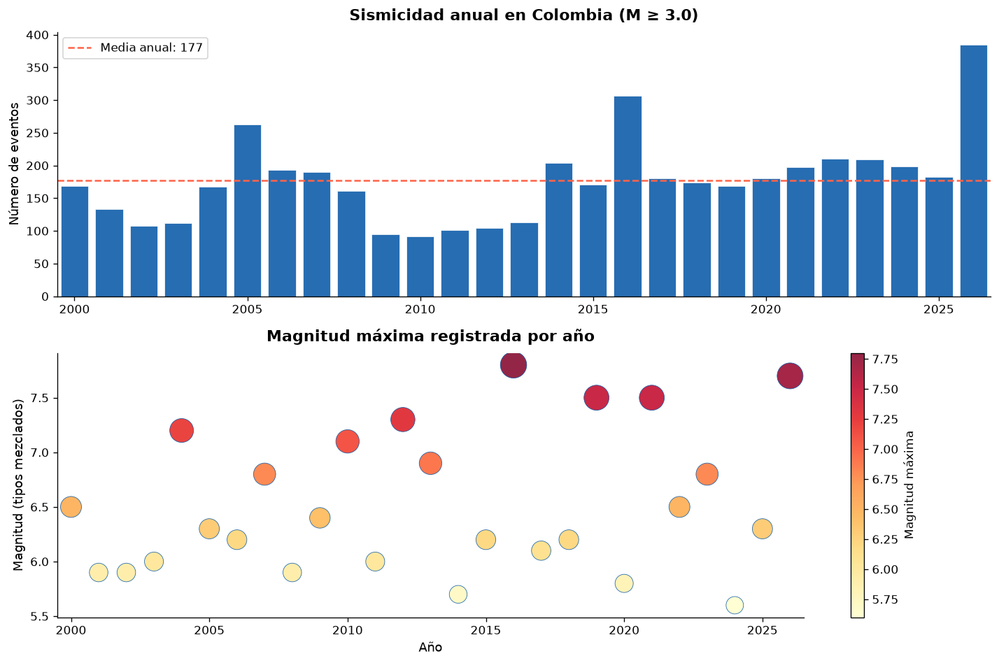

Figura guardada: sismicidad_temporal.png


In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# --- Panel superior: sismos por año ---
sismos_anuales = df.groupby('año').size().reset_index(name='conteo')
axes[0].bar(sismos_anuales['año'], sismos_anuales['conteo'],
            color=UNGRD_BLUE, alpha=0.85, edgecolor='white', linewidth=0.5)
axes[0].axhline(sismos_anuales['conteo'].mean(), color='tomato',
                linestyle='--', linewidth=1.5, label=f"Media anual: {sismos_anuales['conteo'].mean():.0f}")
axes[0].set_title('Sismicidad anual en Colombia (M ≥ 3.0)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_ylabel('Número de eventos', fontsize=11)
axes[0].legend(fontsize=10)
axes[0].set_xlim(1999.5, df['año'].max() + 0.5)

# --- Panel inferior: magnitud máxima por año ---
mag_anual = df.groupby('año')['magnitud'].max().reset_index()
sc = axes[1].scatter(mag_anual['año'], mag_anual['magnitud'],
                     s=mag_anual['magnitud']**2.5 * 3, c=mag_anual['magnitud'],
                     cmap='YlOrRd', alpha=0.85, edgecolors=UNGRD_BLUE, linewidths=0.5)
plt.colorbar(sc, ax=axes[1], label='Magnitud máxima')
axes[1].set_title('Magnitud máxima registrada por año', fontsize=13, fontweight='bold', pad=10)
axes[1].set_ylabel('Magnitud (tipos mezclados)', fontsize=11)
axes[1].set_xlabel('Año', fontsize=11)
axes[1].set_xlim(1999.5, df['año'].max() + 0.5)

plt.tight_layout()
plt.savefig('sismicidad_temporal.png', bbox_inches='tight', dpi=150)
plt.show()
print('Figura guardada: sismicidad_temporal.png')

:::{figure} sismicidad_temporal.png
:label: fig-temporal
:align: center
Distribución temporal de la sismicidad en Colombia (M ≥ 3.0), 2000 a noviembre de 2026 (2026 es un año parcial). Panel superior: número de eventos anuales con la media del período (línea roja). Panel inferior: magnitud máxima registrada por año.
:::

## 6. Relación de Gutenberg-Richter

La relación de **Gutenberg-Richter** ($\log_{10} N = a - b \cdot M$) describe la distribución de magnitudes de una región sísmica: $N$ es el número de sismos de magnitud mayor o igual a $M$. El parámetro *b* (típicamente cercano a 1,0) indica la proporción entre sismos pequeños y grandes: una *b* más alta significa más sismos pequeños por cada grande. Es uno de los insumos fundamentales del Análisis Probabilista de Amenaza Sísmica (PSHA).

El ajuste solo es válido por encima de la **magnitud de completitud** $M_c$, la menor magnitud desde la cual el catálogo registra todos los eventos. La estimamos con el método del máximo de la curvatura (el intervalo de magnitud con más eventos) y calculamos *b* con **máxima verosimilitud** (Aki, 1965; Utsu, 1966), el estimador más usado, con su error estándar. Como comparación, se calcula también por regresión sobre la curva acumulada, que suele sesgar el resultado porque los puntos acumulados no son independientes.

La {numref}`Figura %s <fig-gr>` presenta el ajuste y la magnitud de completitud (ver código en la versión web).

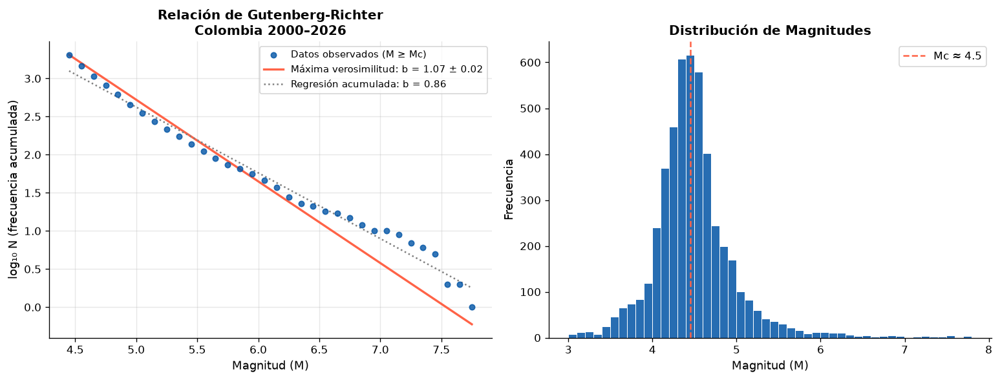

Parámetros Gutenberg-Richter para el catálogo USGS:
   Magnitud de completitud (máximo de curvatura): Mc = 4.5  (n = 2,042 eventos con M ≥ Mc)
   b por máxima verosimilitud: 1.07 ± 0.02   (valor típico ≈ 1,0)
   b por regresión acumulada:  0.86  (R² = 0.983)


In [8]:
def calcular_gutenberg_richter(magnitudes, bin_size=0.1):
    """Estima Mc (máximo de curvatura) y b (máxima verosimilitud de Aki-Utsu y regresión acumulada)."""
    mags = np.asarray(magnitudes)
    bins = np.round(np.arange(mags.min(), mags.max() + bin_size, bin_size), 2)
    conteo, bordes = np.histogram(mags, bins=bins)
    centros = bordes[:-1] + bin_size / 2
    mc = centros[np.argmax(conteo)]                       # magnitud de completitud

    sel = mags[mags >= mc]                                # solo por encima de Mc
    b_ml = np.log10(np.e) / (sel.mean() - (mc - bin_size / 2))
    b_se = b_ml / np.sqrt(len(sel))

    m_ac = centros[centros >= mc]
    acum = np.array([(sel >= m).sum() for m in m_ac])
    ok = acum > 0
    pendiente, intercepto, r, _, _ = stats.linregress(m_ac[ok], np.log10(acum[ok]))
    return dict(mc=mc, n=len(sel), b_ml=b_ml, b_se=b_se, b_ls=-pendiente, a_ls=intercepto,
                r2=r**2, m=m_ac[ok], log_n=np.log10(acum[ok]), centros=centros, conteo=conteo)


gr = calcular_gutenberg_richter(df['magnitud'])
b = gr['b_ml']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Gráfico G-R (por encima de Mc) ---
axes[0].scatter(gr['m'], gr['log_n'], color=UNGRD_BLUE, s=25, alpha=0.8,
                label='Datos observados (M ≥ Mc)', zorder=3)
log_n_mc = gr['log_n'][0]
axes[0].plot(gr['m'], log_n_mc - gr['b_ml'] * (gr['m'] - gr['m'][0]), color='tomato', linewidth=2,
             label=f"Máxima verosimilitud: b = {gr['b_ml']:.2f} ± {gr['b_se']:.2f}")
axes[0].plot(gr['m'], gr['a_ls'] - gr['b_ls'] * gr['m'], color='gray', linewidth=1.5, linestyle=':',
             label=f"Regresión acumulada: b = {gr['b_ls']:.2f}")
axes[0].set_xlabel('Magnitud (M)', fontsize=11)
axes[0].set_ylabel('log₁₀ N (frecuencia acumulada)', fontsize=11)
axes[0].set_title('Relación de Gutenberg-Richter\nColombia 2000–2026', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# --- Histograma de magnitudes con Mc ---
axes[1].bar(gr['centros'], gr['conteo'], width=0.09, color=UNGRD_BLUE, alpha=0.85)
axes[1].axvline(gr['mc'], color='tomato', linestyle='--', linewidth=1.5, label=f"Mc ≈ {gr['mc']:.1f}")
axes[1].set_xlabel('Magnitud (M)', fontsize=11)
axes[1].set_ylabel('Frecuencia', fontsize=11)
axes[1].set_title('Distribución de Magnitudes', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig('gutenberg_richter.png', bbox_inches='tight', dpi=150)
plt.show()

print('Parámetros Gutenberg-Richter para el catálogo USGS:')
print(f"   Magnitud de completitud (máximo de curvatura): Mc = {gr['mc']:.1f}  (n = {gr['n']:,} eventos con M ≥ Mc)")
print(f"   b por máxima verosimilitud: {gr['b_ml']:.2f} ± {gr['b_se']:.2f}   (valor típico ≈ 1,0)")
print(f"   b por regresión acumulada:  {gr['b_ls']:.2f}  (R² = {gr['r2']:.3f})")

:::{figure} gutenberg_richter.png
:label: fig-gr
:align: center
Relación de Gutenberg-Richter para el catálogo USGS de Colombia y su área de influencia, 2000–2026. Izquierda: frecuencia acumulada por encima de la magnitud de completitud, con *b* por máxima verosimilitud (línea roja) y por regresión (línea punteada). Derecha: histograma de magnitudes y magnitud de completitud (Mc).
:::

Si $M_c$ es mayor que 3,0, los sismos entre 3,0 y $M_c$ **no** forman parte del ajuste: incluirlos subestima *b*. Para una tasa de recurrencia se prefiere la máxima verosimilitud, con $\beta = b \ln 10$.

## 7. Análisis de Profundidad Focal

La profundidad focal de un sismo determina en buena medida su radio de afectación y el tipo de daños que puede generar. Colombia presenta una distribución de profundidades amplia y variada, reflejo de los distintos regímenes tectónicos que confluyen en el territorio.

La {numref}`Figura %s <fig-profundidad>` muestra el histograma de profundidades y su relación con la magnitud (ver código en la versión web).

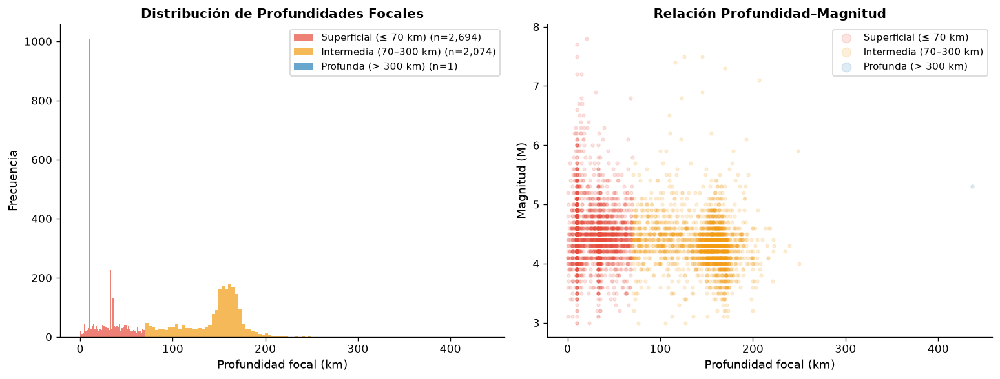

In [9]:
COLORES_PROF = {
    'Superficial (≤ 70 km)':    '#e74c3c',
    'Intermedia (70–300 km)':   '#f39c12',
    'Profunda (> 300 km)':      '#2980b9',
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Histograma de profundidades ---
for clase, color in COLORES_PROF.items():
    subset = df[df['clase_profundidad'] == clase]
    axes[0].hist(subset['profundidad_km'], bins=50, alpha=0.7, color=color,
                 label=f'{clase} (n={len(subset):,})', edgecolor='none')
axes[0].set_xlabel('Profundidad focal (km)', fontsize=11)
axes[0].set_ylabel('Frecuencia', fontsize=11)
axes[0].set_title('Distribución de Profundidades Focales', fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)

# --- Magnitud vs. Profundidad ---
for clase, color in COLORES_PROF.items():
    subset = df[df['clase_profundidad'] == clase]
    axes[1].scatter(subset['profundidad_km'], subset['magnitud'],
                    alpha=0.15, s=8, color=color, label=clase)
axes[1].set_xlabel('Profundidad focal (km)', fontsize=11)
axes[1].set_ylabel('Magnitud (M)', fontsize=11)
axes[1].set_title('Relación Profundidad–Magnitud', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9, markerscale=3)

plt.tight_layout()
plt.savefig('profundidad_focal.png', bbox_inches='tight', dpi=150)
plt.show()

:::{figure} profundidad_focal.png
:label: fig-profundidad
:align: center
Distribución de profundidades focales en Colombia 2000–2026. Izquierda: histograma por clase de profundidad (superficial, intermedia, profunda). Derecha: relación profundidad–magnitud por clase.
:::

## 8. Sismos Más Significativos

Identificamos los eventos de mayor magnitud del período analizado, que incluye los sismos de 2026 hasta la fecha de ejecución del cuaderno, y los contextualizamos dentro del marco tectónico de Colombia. La {numref}`Tabla %s <tbl-top>` lista los 15 mayores sismos del catálogo con el lugar de cada uno (ver código en la versión web); varios ocurrieron fuera de Colombia.

In [10]:
# Top 15 eventos por magnitud
top_sismos = df.nlargest(15, 'magnitud')[['tiempo', 'magnitud', 'profundidad_km',
                                           'clase_profundidad', 'latitud', 'longitud', 'lugar']]
top_sismos['tiempo'] = top_sismos['tiempo'].dt.strftime('%Y-%m-%d %H:%M UTC')
top_sismos = top_sismos.reset_index(drop=True)
top_sismos.index += 1
top_sismos.columns = ['Fecha/Hora', 'Magnitud', 'Prof. (km)', 'Clase', 'Lat', 'Lon', 'Lugar']

In [11]:
top_sismos

,Fecha/Hora,Magnitud,Prof. (km),Clase,Lat,Lon,Lugar
1,2016-04-16 23:58 UTC,7.8,20.59,Superficial (≤ 70 km),0.3819,-79.9218,"27 km SSE of Muisne, Ecuador"
2,2026-10-09 17:56 UTC,7.7,10.00,Superficial (≤ 70 km),7.6069,-80.7566,"10 km WSW of Pitaloza Arriba, Panama"
3,2026-06-24 22:05 UTC,7.5,10.00,Superficial (≤ 70 km),10.5955,-67.2205,"20 km W of Catia La Mar, Venezuela"
4,2021-11-28 10:52 UTC,7.5,126.00,Intermedia (70–300 km),-4.4667,-76.8126,"43 km NNW of Barranca, Peru"
5,2019-02-22 10:17 UTC,7.5,145.00,Intermedia (70–300 km),-2.1862,-77.0505,"115 km ESE of Palora, Ecuador"
6,2026-08-10 12:34 UTC,7.4,116.13,Intermedia (70–300 km),4.8601,-76.2558,"4 km SSW of San José del Palmar, Colombia"
7,2012-09-30 16:31 UTC,7.3,170.00,Intermedia (70–300 km),1.9290,-76.3620,"11 km WNW of San Agustín, Colombia"
8,2026-06-24 22:04 UTC,7.2,10.00,Superficial (≤ 70 km),10.3713,-68.5564,"20 km E of San Felipe, Venezuela"
9,2004-11-15 09:06 UTC,7.2,15.00,Superficial (≤ 70 km),4.6950,-77.5080,"32 km SSW of Pizarro, Colombia"
10,2010-08-12 11:54 UTC,7.1,206.70,Intermedia (70–300 km),-1.2660,-77.3060,Ecuador


:::{table} Los 15 mayores sismos del catálogo USGS en la caja de búsqueda, 2000–2026.
:label: tbl-top

```{embed} #cell-tbl-top
:remove-input: true
```

Lat y Lon, latitud y longitud del epicentro en grados; la columna Lugar es la descripción del USGS e indica el país.
:::

## 9. Mapa Interactivo de Epicentros

El siguiente mapa muestra la distribución espacial de los epicentros. El tamaño de cada círculo es proporcional a la magnitud y el color indica la profundidad focal. El mapa interactivo de la versión web permite acercarse a cada región y consultar los datos de cada evento. No se reproduce en el PDF (ver código en la versión web).

In [12]:
def color_por_profundidad(profundidad):
    if profundidad <= 70:    return '#e74c3c'   # rojo — superficial
    elif profundidad <= 300: return '#f39c12'   # naranja — intermedia
    else:                    return '#2980b9'   # azul — profunda

# Centrar mapa en Colombia
mapa = folium.Map(
    location=[4.5, -74.0],
    zoom_start=5,
    tiles='OpenStreetMap'
)

# Usar solo M >= 4.0 para no sobrecargar el mapa
df_mapa = df[df['magnitud'] >= 4.0].copy()

# Capa de calor (heatmap) de todos los eventos M >= 3.0
heat_data = df[['latitud', 'longitud', 'magnitud']].values.tolist()
HeatMap(heat_data, name='Densidad sísmica (M ≥ 3.0)',
        radius=6, blur=8, max_zoom=8).add_to(mapa)

# Capa de marcadores para M >= 4.0
cluster = MarkerCluster(name='Epicentros M ≥ 4.0')
for _, row in df_mapa.iterrows():
    radio = max(3, row['magnitud'] ** 2.2 * 0.5)
    popup_txt = (
        f"<b>Magnitud:</b> M {row['magnitud']:.1f}<br>"
        f"<b>Profundidad:</b> {row['profundidad_km']:.0f} km ({row['clase_profundidad']})<br>"
        f"<b>Fecha:</b> {str(row['tiempo'])[:10]}<br>"
        f"<b>Lugar:</b> {row['lugar']}"
    )
    folium.CircleMarker(
        location=[row['latitud'], row['longitud']],
        radius=radio,
        color=color_por_profundidad(row['profundidad_km']),
        fill=True, fill_opacity=0.65, weight=0.5,
        popup=folium.Popup(popup_txt, max_width=280),
        tooltip=f"M {row['magnitud']:.1f}"
    ).add_to(cluster)

cluster.add_to(mapa)

# Leyenda
leyenda_html = """
<div style="position:fixed; bottom:30px; left:30px; z-index:1000;
     background:white; padding:12px 16px; border-radius:8px;
     box-shadow:0 2px 8px rgba(0,0,0,0.2); font-size:12px; font-family:sans-serif;">
  <b>Profundidad focal</b><br>
  <span style='color:#e74c3c;'>●</span> Superficial ≤ 70 km<br>
  <span style='color:#f39c12;'>●</span> Intermedia 70–300 km<br>
  <span style='color:#2980b9;'>●</span> Profunda > 300 km<br>
  <hr style='margin:6px 0; border-color:#eee;'>
  <small>Tamaño ∝ Magnitud · Catálogo USGS 2000–2026</small>
</div>
"""
mapa.get_root().html.add_child(folium.Element(leyenda_html))
folium.LayerControl().add_to(mapa)

# Guardar y mostrar
mapa.save('mapa_sismicidad_colombia.html')
print(f'✅ Mapa generado con {len(df_mapa):,} epicentros (M ≥ 4.0)')
print('   Abre mapa_sismicidad_colombia.html para visualización interactiva')
_html = mapa._repr_html_().replace('Make this Notebook Trusted to load map: File -> Trust Notebook', '')
from IPython.display import HTML
HTML(_html)

✅ Mapa generado con 4,329 epicentros (M ≥ 4.0)
   Abre mapa_sismicidad_colombia.html para visualización interactiva


## 10. Animación temporal a ritmo constante

La animación recorre la sismicidad de 1900 a 2026 con el mismo número de años por cuadro, de modo que el reloj avanza a velocidad constante, y compara dos paneles con el mismo reloj: a la izquierda, todo el catálogo; a la derecha, solo los sismos por encima de la magnitud de completitud. Si el aumento del panel izquierdo fuera actividad real, el derecho crecería igual; la advertencia va dentro de la imagen. Cada círculo es un sismo: su tamaño indica la magnitud y su color la profundidad focal (la escala se satura en 200 km). La animación se reproduce en la versión web y no en el PDF, que muestra el último cuadro (ver código en la versión web).

La animación usa un **catálogo histórico ampliado**: sismos de 1900 a 2026 con magnitud de 2,5 o más en un cuadrante algo mayor (84° O a 66° O y 5° S a 16° N, el mismo de Montejo et al., 2023), más los sismos anteriores a 1900 de la base de sismos significativos de NOAA/NCEI. La API del USGS entrega como máximo 20 000 eventos por consulta, así que la descarga se hace por décadas y cualquier tramo saturado se divide en dos. Este catálogo se usa también en las secciones 12 a 15.

:::{note} Una descarga distinta a la de las secciones 3 a 9
El catálogo de las secciones 3 a 9 y 11 (2000–hoy, magnitud ≥ 3,0, 5° S a 13° N y 82° O a 65° O) no cambia. El catálogo ampliado tiene otro cuadrante y otro umbral de magnitud, por lo que sus conteos no son comparables con los de esas secciones.
:::

In [13]:
from datetime import date
import io, json, time

# ---------------- Parámetros del catálogo ampliado ----------------
BBOX = dict(lon_min=-84.0, lon_max=-66.0, lat_min=-5.0, lat_max=16.0)   # cuadrante de Montejo et al. (2023)
ANIO_INI = 1900          # inicio del catálogo instrumental
FECHA_FIN = date.today().isoformat()
MAG_MIN = 2.5            # magnitud mínima de descarga
MAG_COMPLETA = 4.5       # umbral "completo" para comparar tasas
PROF_MAX = 200           # profundidad máxima de los cortes (km)
EXAG_VERTICAL = 3        # exageración vertical de los cortes

ANIO_FIN = pd.Timestamp(FECHA_FIN).year + (pd.Timestamp(FECHA_FIN).dayofyear - 1) / 365.25
LAT_MEDIA = (BBOX["lat_min"] + BBOX["lat_max"]) / 2
KM_LAT = 110.57
KM_LON = 111.32 * np.cos(np.radians(LAT_MEDIA))

def miles(n):
    """Entero con espacio como separador de miles."""
    return f"{int(n):,}".replace(",", " ")

def dec(x):
    """Número con coma decimal."""
    return f"{x:g}".replace(".", ",")

LIMITE = 20000

def _usgs_tramo(t0, t1):
    """Descarga un tramo temporal; si llega al límite, lo divide en dos."""
    params = dict(format="csv", orderby="time-asc", limit=LIMITE, eventtype="earthquake",
                  starttime=t0.strftime("%Y-%m-%dT%H:%M:%S"), endtime=t1.strftime("%Y-%m-%dT%H:%M:%S"),
                  minlatitude=BBOX["lat_min"], maxlatitude=BBOX["lat_max"],
                  minlongitude=BBOX["lon_min"], maxlongitude=BBOX["lon_max"], minmagnitude=MAG_MIN)
    for intento in range(4):
        r = requests.get(API_URL, params=params, timeout=180)
        if r.status_code in (200, 204):
            break
        time.sleep(5 * (intento + 1))
    r.raise_for_status()
    if r.status_code == 204 or not r.text.strip():
        return pd.DataFrame()
    d = pd.read_csv(io.StringIO(r.text))
    if len(d) >= LIMITE:
        tm = t0 + (t1 - t0) / 2
        return pd.concat([_usgs_tramo(t0, tm), _usgs_tramo(tm, t1)], ignore_index=True)
    return d

partes, t, fin = [], pd.Timestamp(year=ANIO_INI, month=1, day=1), pd.Timestamp(FECHA_FIN)
while t < fin:
    t2 = min(t + pd.DateOffset(years=10), fin)
    partes.append(_usgs_tramo(t, t2))
    t = t2
crudo = pd.concat([p for p in partes if len(p)], ignore_index=True).drop_duplicates("id")

tt = pd.to_datetime(crudo["time"], utc=True, format="ISO8601")
dias = np.where(tt.dt.is_leap_year, 366, 365)
usgs = pd.DataFrame({
    "anio_dec": tt.dt.year + (tt.dt.dayofyear - 1 + tt.dt.hour / 24) / dias,
    "fecha": tt.dt.strftime("%Y-%m-%d"),
    "lat": crudo["latitude"], "lon": crudo["longitude"], "prof_km": crudo["depth"],
    "mag": crudo["mag"], "lugar": crudo["place"], "fuente": "USGS", "historico": False})
print(f"USGS: {miles(len(usgs))} eventos de magnitud {dec(MAG_MIN)} o más, {usgs.fecha.min()} a {usgs.fecha.max()}")

USGS: 11 085 eventos de magnitud 2,5 o más, 1900-10-29 a 2026-11-15


In [14]:
NOAA_URL = "https://www.ngdc.noaa.gov/hazel/hazard-service/api/v1/earthquakes"
COLS_NOAA = ["year", "month", "day", "latitude", "longitude", "eqDepth", "eqMagnitude", "locationName", "deaths"]

noaa = pd.DataFrame()
try:
    filas, pag, total = [], 1, 1
    while pag <= total:
        r = requests.get(NOAA_URL, params=dict(country="COLOMBIA", page=pag), timeout=120)
        r.raise_for_status()
        js = r.json()
        filas += js.get("items", [])
        total = int(js.get("totalPages", 1) or 1)
        pag += 1
    d = pd.DataFrame(filas).reindex(columns=COLS_NOAA)
    mes, dia = d["month"].fillna(7), d["day"].fillna(15)
    lugar = (d["locationName"].fillna("").astype(str)
             .str.split(":").str[-1].str.split(",").str[:2].str.join(",").str.replace(r"\s+", " ", regex=True)
             .str.replace(",", ", ").str.replace(r",\s+", ", ", regex=True).str.strip().str.title())
    noaa = pd.DataFrame({
        "anio_dec": d["year"] + (mes - 1) / 12 + (dia - 1) / 365.25,
        "fecha": (d["year"].astype("Int64").astype(str) + "-" + mes.astype(int).astype(str).str.zfill(2)
                  + "-" + dia.astype(int).astype(str).str.zfill(2)),
        "lat": d["latitude"], "lon": d["longitude"], "prof_km": d["eqDepth"], "mag": d["eqMagnitude"],
        "lugar": lugar, "fuente": "NOAA", "historico": d["year"] < ANIO_INI, "muertes": d["deaths"]})
    print(f"NOAA: {len(noaa)} sismos significativos, {int(noaa.anio_dec.min())}–{int(noaa.anio_dec.max())}")
except Exception as e:
    print(f"No se pudo obtener la base de NOAA ({type(e).__name__}: {e}). Se continúa sin históricos.")
    noaa = pd.DataFrame(columns=["anio_dec", "fecha", "lat", "lon", "prof_km", "mag", "lugar", "fuente", "historico", "muertes"])

# Catálogo unificado: USGS instrumental + históricos de NOAA anteriores a ANIO_INI
cat = pd.concat([usgs, noaa[noaa.historico].drop(columns="muertes")], ignore_index=True)
cat = cat[cat.lon.between(BBOX["lon_min"], BBOX["lon_max"]) & cat.lat.between(BBOX["lat_min"], BBOX["lat_max"])]
cat = cat.dropna(subset=["anio_dec", "lat", "lon", "mag"]).sort_values("anio_dec").reset_index(drop=True)
cat["anio"] = np.floor(cat.anio_dec).astype(int)
inst = cat[~cat.historico]

# Sismo de referencia: el mayor de agosto de 2026 en el catálogo del USGS
_ref = usgs[(usgs.fecha >= "2026-08-01") & (usgs.fecha <= "2026-08-31")].nlargest(1, "mag")
EVENTO_REF = dict(nombre="San José del Palmar, 10-ago-2026", lat=float(_ref.lat.iloc[0]), lon=float(_ref.lon.iloc[0]),
                  prof_km=float(_ref.prof_km.iloc[0]), mag=float(_ref.mag.iloc[0]))
FUENTES = {"USGS": "USGS ComCat", "NOAA": "NOAA/NCEI"}
CREDITO = "Datos: " + ", ".join(FUENTES[f] for f in sorted(cat.fuente.unique())) + "."

print(f"Catálogo unificado: {miles(len(cat))} eventos, {cat.anio.min()}–{cat.anio.max()}; "
      f"{miles(cat.prof_km.isna().sum())} sin profundidad conocida")
print(f"Sismo de referencia: M {EVENTO_REF['mag']:.1f}, {EVENTO_REF['prof_km']:.0f} km de profundidad")

NOAA: 83 sismos significativos, 1566–2026
Catálogo unificado: 11 097 eventos, 1566–2026; 10 sin profundidad conocida
Sismo de referencia: M 7.4, 116 km de profundidad


In [15]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

URL_PAISES = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/"
              "ne_50m_admin_0_countries.geojson")
_paises = requests.get(URL_PAISES, timeout=120).json()["features"]

def anillos(feature):
    """Anillos exteriores de un país (Polygon o MultiPolygon) como listas de (lon, lat)."""
    g = feature["geometry"]
    polis = [g["coordinates"]] if g["type"] == "Polygon" else g["coordinates"]
    return [np.array(p[0]) for p in polis]

anillos_paises = {f["properties"]["ADMIN"]: anillos(f) for f in _paises}
colombia = anillos_paises["Colombia"]

CMAP = LinearSegmentedColormap.from_list("profundidad", ["#fde3df", "#f6a6b2", "#c2408c", "#6a1b7a", "#1b0b2e"])
NORM = Normalize(0, PROF_MAX)

def tam(mag):
    """Área del marcador: crece exponencialmente con la magnitud (M2≈1, M4≈8, M6≈57, M8≈430)."""
    return 2.75 ** (np.clip(np.asarray(mag, dtype=float), 2, 9.5) - 2)

def mapa_base(ax):
    ax.set_facecolor("#b7cde8")
    for nombre, polis in anillos_paises.items():
        for p in polis:
            if (p[:, 0].max() < BBOX["lon_min"] - 6 or p[:, 0].min() > BBOX["lon_max"] + 6
                    or p[:, 1].max() < BBOX["lat_min"] - 6 or p[:, 1].min() > BBOX["lat_max"] + 6):
                continue
            col, lw = ("#7d9189", 0.9) if nombre == "Colombia" else ("#8a9c95", 0.5)
            ax.fill(p[:, 0], p[:, 1], color=col, ec="k" if nombre == "Colombia" else "#333", lw=lw)
    ax.set_xlim(BBOX["lon_min"], BBOX["lon_max"]); ax.set_ylim(BBOX["lat_min"], BBOX["lat_max"])
    ax.set_aspect(1 / np.cos(np.radians(LAT_MEDIA)))
    ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(True)

def leyenda_magnitud(ax, loc="lower left"):
    marcas = [ax.scatter([], [], s=tam(m), color="0.2", label=f"M{m}") for m in (4, 6, 8)]
    hueco = ax.scatter([], [], s=40, facecolors="none", edgecolors="0.25", linewidths=0.8, label="Prof. desconocida")
    ax.legend(handles=marcas + [hueco], loc=loc, fontsize=7, frameon=True, framealpha=0.85,
              labelspacing=1.1, borderpad=0.9)

In [16]:
from matplotlib import animation

ANIM_INI = 1900       # año de inicio de la animación
ANIOS_POR_CUADRO = 1  # años que avanza cada cuadro
FPS = 12              # cuadros por segundo

# Codificador de video: el del sistema o, si no hay, el que trae el paquete imageio-ffmpeg
import shutil
if not shutil.which("ffmpeg"):
    try:
        import imageio_ffmpeg
        plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    except Exception:
        pass

def animar(df, mag_completa=MAG_COMPLETA, anio_ini=ANIM_INI, paso=ANIOS_POR_CUADRO, fps=FPS):
    df = df[df.anio_dec >= anio_ini].sort_values("anio_dec")
    grupos = [df, df[df.mag >= mag_completa]]
    titulos = ["Todo el catálogo", f"Solo M ≥ {dec(mag_completa)}"]
    hay_video = animation.writers.is_available("ffmpeg")
    if not hay_video:
        paso = max(paso, 2)                                   # el GIF pesa mucho: menos cuadros
    tiempos = np.append(np.arange(anio_ini, ANIO_FIN, paso), [ANIO_FIN] * fps)   # pausa final de 1 s

    fig, axs = plt.subplots(1, 2, figsize=(10, 6.3), dpi=90)
    cmap = CMAP.copy(); cmap.set_bad("0.35")
    capas = []
    for ax, g, titulo in zip(axs, grupos, titulos):
        mapa_base(ax); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(labelsize=7)
        ax.set_title(titulo, fontsize=11, fontweight="bold")
        sc = ax.scatter([], [], s=[], c=[], cmap=cmap, norm=NORM, alpha=0.75, linewidths=0)
        txt = ax.text(0.03, 0.03, "", transform=ax.transAxes, fontsize=10,
                      bbox=dict(fc="white", ec="none", alpha=0.8))
        capas.append((sc, txt, g.anio_dec.to_numpy(), g[["lon", "lat"]].to_numpy(),
                      tam(g.mag), np.ma.masked_invalid(g.prof_km.to_numpy(dtype=float))))
    reloj = fig.suptitle("", fontsize=16, fontweight="bold", y=0.98)
    fig.text(0.5, 0.015, "El aumento del panel izquierdo refleja mejor monitoreo, no más actividad sísmica. "
             + CREDITO, ha="center", fontsize=8.5)
    fig.subplots_adjust(left=0.05, right=0.98, top=0.9, bottom=0.08, wspace=0.12)

    def actualizar(i):
        t = tiempos[i]
        for sc, txt, tt, xy, s, c in capas:
            k = np.searchsorted(tt, t, side="right")
            sc.set_offsets(xy[:k]); sc.set_sizes(s[:k]); sc.set_array(c[:k])
            txt.set_text(f"{miles(k)} sismos")
        reloj.set_text(str(int(t)))
        return [c[0] for c in capas]

    anim = animation.FuncAnimation(fig, actualizar, frames=len(tiempos), interval=1000 / fps)
    if hay_video:
        salida = "animacion_sismicidad.mp4"
        anim.save(salida, writer=animation.FFMpegWriter(fps=fps, bitrate=1600))
    else:
        salida = "animacion_sismicidad.gif"
        anim.save(salida, writer=animation.PillowWriter(fps=fps))
    actualizar(len(tiempos) - 1)                               # último cuadro como figura fija
    fig.savefig("animacion_ultimo_cuadro.png", dpi=160)
    plt.close(fig)
    return salida

archivo_anim = animar(cat)
print("Animación guardada en", archivo_anim)

Animación guardada en animacion_sismicidad.mp4


In [17]:
from IPython.display import Video, Image, display
if archivo_anim.endswith(".mp4"):
    display(Video(archivo_anim, embed=True, html_attributes="controls loop muted playsinline"))
else:
    display(Image(filename=archivo_anim))

:::{figure} animacion_ultimo_cuadro.png
:label: fig-animacion
:align: center
:alt: Último cuadro de la animación de la sismicidad, con todo el catálogo y solo los sismos de magnitud 4,5 o más
Último cuadro de la animación de la sismicidad de Colombia y territorios vecinos, 1900–2026. Izquierda: todo el catálogo ampliado. Derecha: solo los sismos de magnitud 4,5 o más. El tamaño del círculo indica la magnitud y el color la profundidad focal (saturada en 200 km); el contador es el número acumulado de sismos de cada panel.
:::

## 11. Variación Estacional de la Sismicidad

La sismicidad tectónica no debería mostrar una variación estacional marcada. Este análisis revisa si el número de eventos y la magnitud media cambian por mes. Las diferencias que aparezcan **no** prueban un efecto del clima: los sismos grandes generan réplicas que concentran eventos en meses específicos, y el catálogo no está declustered (sin separar réplicas). Una relación con la lluvia requeriría eliminar las réplicas y una prueba estadística. La {numref}`Figura %s <fig-estacional>` muestra el resultado (ver código en la versión web).

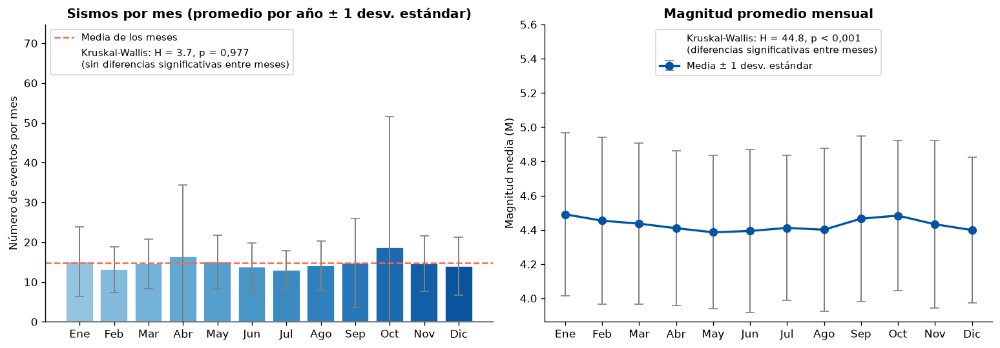

In [18]:
meses_nombres = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun',
                 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

def texto_prueba(grupos):
    """Kruskal-Wallis entre meses (no paramétrica): H, p y conclusión al 5 %."""
    H, p = stats.kruskal(*grupos)
    p_txt = 'p < 0,001' if p < 0.001 else f'p = {p:.3f}'.replace('.', ',')
    concl = 'diferencias significativas' if p < 0.05 else 'sin diferencias significativas'
    return f'Kruskal-Wallis: H = {H:.1f}, {p_txt}\n({concl} entre meses)'

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

# --- Sismos por mes: promedio por año ± 1 desviación estándar entre años ---
# Solo meses completos: se excluye el mes en curso del último año
ult = df['tiempo'].max()
completos = df[(df['año'] < ult.year) | (df['mes'] < ult.month)]
conteo = completos.groupby(['año', 'mes']).size().unstack(fill_value=0)   # años × meses
conteo = conteo.reindex(columns=range(1, 13))
conteo = conteo.loc[:, conteo.columns]
# Los años con meses sin cubrir (el año en curso) no aportan a esos meses
for m in range(ult.month, 13):
    conteo.loc[ult.year, m] = np.nan
prom_mes = conteo.mean()
sd_cont = conteo.std()
axes[0].bar(range(1, 13), prom_mes.values, yerr=sd_cont.values, capsize=4,
            color=[plt.cm.Blues(0.4 + 0.5 * i / 12) for i in range(12)],
            edgecolor='white', error_kw=dict(elinewidth=1.2, ecolor='gray'))
axes[0].axhline(prom_mes.mean(), color='tomato', linestyle='--', linewidth=1.5,
                label='Media de los meses')
axes[0].plot([], [], ' ', label=texto_prueba([conteo[m].dropna().values for m in range(1, 13)]))
axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels(meses_nombres)
axes[0].set_title('Sismos por mes (promedio por año ± 1 desv. estándar)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Número de eventos por mes')
axes[0].set_ylim(0, (prom_mes + sd_cont).max() * 1.45)
axes[0].legend(fontsize=9, loc='upper left')

# --- Magnitud media mensual ---
mag_mes = df.groupby('mes')['magnitud'].mean()
sd_mes = df.groupby('mes')['magnitud'].std()
axes[1].errorbar(mag_mes.index, mag_mes.values, yerr=sd_mes.values, fmt='o-',
                 color=UNGRD_BLUE, linewidth=2, markersize=7, capsize=4,
                 elinewidth=1.2, ecolor='gray', label='Media ± 1 desv. estándar')
axes[1].plot([], [], ' ', label=texto_prueba([g['magnitud'].values for _, g in df.groupby('mes')]))
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(meses_nombres)
axes[1].set_title('Magnitud promedio mensual', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Magnitud media (M)')
axes[1].set_ylim(top=5.6)
axes[1].legend(fontsize=9, loc='upper center')

plt.tight_layout()
plt.savefig('variacion_estacional.png', bbox_inches='tight', dpi=150)
plt.show()


:::{figure} variacion_estacional.png
:label: fig-estacional
:align: center
Variación estacional de la sismicidad en Colombia, 2000–2026. Izquierda: promedio de eventos por mes del año (meses completos) con ±1 desviación estándar entre años. Derecha: magnitud promedio mensual con ±1 desviación estándar de la magnitud. En ambos paneles, la leyenda indica el resultado de la prueba de Kruskal-Wallis (H, valor p) entre los 12 meses.
:::

La prueba de Kruskal-Wallis, que no supone una distribución normal, compara los meses entre sí. El número de eventos por mes no muestra diferencias significativas, mientras que la magnitud sí las muestra, pero la diferencia entre las medias mensuales es de apenas una décima de magnitud y se detecta por el gran número de eventos. Como las réplicas no son independientes, el valor *p* debe leerse como indicativo, no como prueba de un efecto estacional.


## 12. Sismos históricos y completitud en el tiempo

El catálogo ampliado de la sección 10 (USGS de 1900 a 2026 y sismos significativos de NOAA/NCEI) permite saber si el número de sismos cambia por la actividad real o por la instrumentación. Esta sección lo usa para identificar los sismos con más víctimas y para estimar la completitud en el tiempo (ver código en la versión web).

### 12.1 Sismos históricos y víctimas (NOAA/NCEI)

La base de sismos significativos de NOAA (descargada en la sección 10) aporta los eventos anteriores a 1900 y, para todo el periodo, las víctimas reportadas. Eso permite identificar los sismos por su **impacto** y no solo por su magnitud. En los eventos históricos la magnitud proviene de intensidades macrosísmicas y casi nunca se conoce la profundidad. La {numref}`Tabla %s <tbl-victimas>` lista los ocho con más víctimas (ver código en la versión web).

In [19]:
_v = noaa.dropna(subset=["muertes"]).nlargest(8, "muertes").copy()
_t = pd.DataFrame({
    "Fecha": _v["fecha"],
    "Lugar": _v["lugar"],
    "Magnitud": ["—" if pd.isna(m) else f"{m:.1f}".replace(".", ",") for m in _v["mag"]],
    "Víctimas mortales": [miles(m) for m in _v["muertes"]]}).reset_index(drop=True)
_t.index += 1
_t

,Fecha,Lugar,Magnitud,Víctimas mortales
1,1999-01-25,"Armenia, Calarca","6,2",1 185
2,1875-05-18,"Cucuta, San Cayetano","7,5",1 001
3,1994-06-06,"Cauca, Huila","6,8",650
4,1979-12-12,"Off Shore, Pacific Ocean","8,1",600
5,1983-03-31,"Sw, Popayan","4,9",350
6,2026-08-10,Choco,"7,4",335
7,1923-12-14,Ipiales,"6,2",300
8,1950-07-09,Anboledas,"6,1",300


:::{table} Los ocho sismos con más víctimas mortales en la base de sismos significativos de NOAA/NCEI para Colombia.
:label: tbl-victimas

```{embed} #cell-tbl-victimas
:remove-input: true
```

Fecha con mes y día asumidos (julio y 15) cuando la base no los registra; Lugar, región indicada por NOAA; Magnitud, de tipos mezclados (en los eventos históricos, derivada de intensidades); — indica que no se reporta.
:::

### 12.2 Completitud en el tiempo

La magnitud de completitud ($M_c$) es el umbral sobre el cual el catálogo registra prácticamente todos los sismos. Se estima aquí por máxima curvatura (el intervalo de magnitud más frecuente, más una corrección de 0,2; Wiemer y Wyss, 2000) en ventanas de cinco años, lo que da una estimación gruesa, suficiente para elegir un umbral de filtrado. La {numref}`Figura %s <fig-acumulado>` muestra el acumulado de sismos según el umbral de magnitud: si el crecimiento fuera actividad real, las tres curvas subirían por igual; lo que ocurre es que solo se dispara la de todos los eventos, con saltos en los años en que cambia la instrumentación. La {numref}`Figura %s <fig-mc-tiempo>` presenta $M_c$ en el tiempo y la {numref}`Figura %s <fig-tasa>` la tasa anual de sismos por umbral (ver código en la versión web).

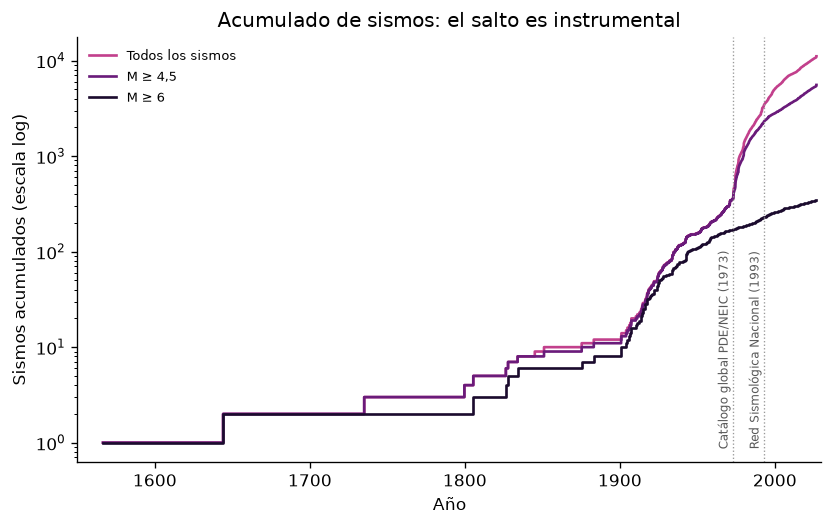

Eventos desde 1973: 96.8 % del catálogo
Eventos desde 1993: 69.2 % del catálogo


In [20]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

HITOS = {1973: "Catálogo global PDE/NEIC (1973)", 1993: "Red Sismológica Nacional (1993)"}
fig, ax = plt.subplots(figsize=(8, 4.6))
for umbral, color in [(None, "#c2408c"), (MAG_COMPLETA, "#6a1b7a"), (6.0, "#1b0b2e")]:
    sub = cat if umbral is None else cat[cat.mag >= umbral]
    etiqueta = "Todos los sismos" if umbral is None else f"M ≥ {dec(umbral)}"
    ax.step(sub.anio_dec, np.arange(1, len(sub) + 1), where="post", color=color, lw=1.6, label=etiqueta)
for anio, texto in HITOS.items():
    ax.axvline(anio, color="0.6", lw=0.8, ls=":")
    ax.text(anio - 1.5, 0.03, texto, transform=ax.get_xaxis_transform(), rotation=90,
            ha="right", va="bottom", fontsize=7, color="0.35")
ax.set(yscale="log", xlim=(1550, 2030), xlabel="Año", ylabel="Sismos acumulados (escala log)",
       title="Acumulado de sismos: el salto es instrumental")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.savefig("completitud_acumulado.png", bbox_inches="tight", dpi=200); plt.show()

n = len(cat)
for anio in (1973, 1993):
    print(f"Eventos desde {anio}: {100 * (cat.anio >= anio).sum() / n:.1f} % del catálogo")

:::{figure} completitud_acumulado.png
:label: fig-acumulado
:align: center
:alt: Acumulado de sismos en escala logarítmica por umbral de magnitud
Sismos acumulados en el catálogo ampliado (USGS desde 1900 y NOAA/NCEI antes), en escala logarítmica, para todos los eventos y para los de magnitud 4,5 o más y 6,0 o más. Las líneas punteadas marcan el inicio del catálogo global PDE/NEIC (1973) y de la Red Sismológica Nacional (1993).
:::

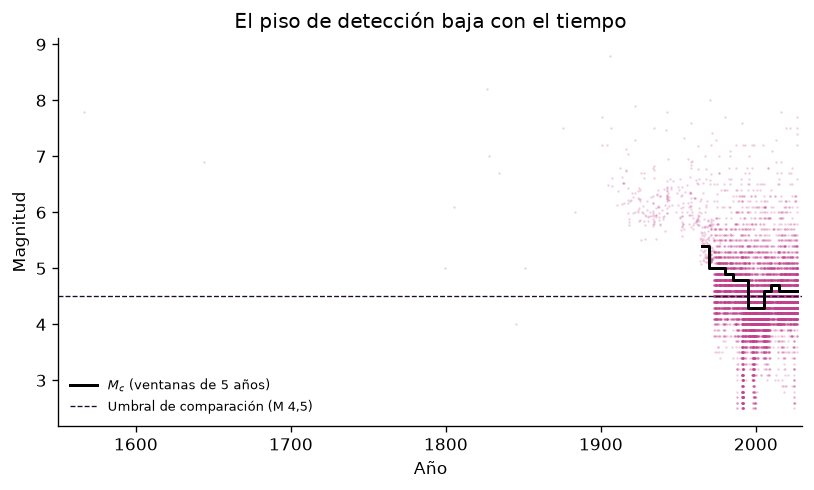

,1965,1970,1975,1980,1985,1990,1995,2000,2005,2010,2015,2020,2025
Mc,5.4,5.0,5.0,4.9,4.8,4.8,4.3,4.3,4.6,4.7,4.6,4.6,4.6


In [21]:
def mc_maxc(mags, paso=0.1, correccion=0.2, n_min=50):
    """Magnitud de completitud por máxima curvatura (Wiemer y Wyss, 2000)."""
    m = np.round(pd.Series(mags).dropna().to_numpy(), 1)
    if len(m) < n_min:
        return np.nan
    bordes = np.arange(m.min() - paso / 2, m.max() + paso, paso)
    h, _ = np.histogram(m, bins=bordes)
    return round(bordes[np.argmax(h)] + paso / 2 + correccion, 1)

ventanas = np.arange(1960, int(ANIO_FIN) + 1, 5)
mc = pd.Series({a: mc_maxc(inst.loc[inst.anio.between(a, a + 4), "mag"]) for a in ventanas}, name="Mc")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(cat.anio_dec, cat.mag, s=2, alpha=0.25, color="#c2408c", linewidths=0, rasterized=True)
ax.step(list(mc.index) + [ANIO_FIN], list(mc.values) + [mc.values[-1]], where="post", color="k", lw=1.8,
        label="$M_c$ (ventanas de 5 años)")
ax.axhline(MAG_COMPLETA, color="#1b0b2e", lw=0.8, ls="--", label=f"Umbral de comparación (M {dec(MAG_COMPLETA)})")
ax.set(xlim=(1550, 2030), xlabel="Año", ylabel="Magnitud", title="El piso de detección baja con el tiempo")
ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.savefig("completitud_mc_tiempo.png", bbox_inches="tight", dpi=200); plt.show()
mc.dropna().to_frame().T

:::{figure} completitud_mc_tiempo.png
:label: fig-mc-tiempo
:align: center
:alt: Magnitud de los sismos en el tiempo y magnitud de completitud por ventanas de cinco años
Magnitud de cada sismo del catálogo ampliado (puntos) y magnitud de completitud $M_c$ por ventanas de cinco años (línea negra). La línea discontinua es el umbral de magnitud 4,5 usado para comparar tasas.
:::

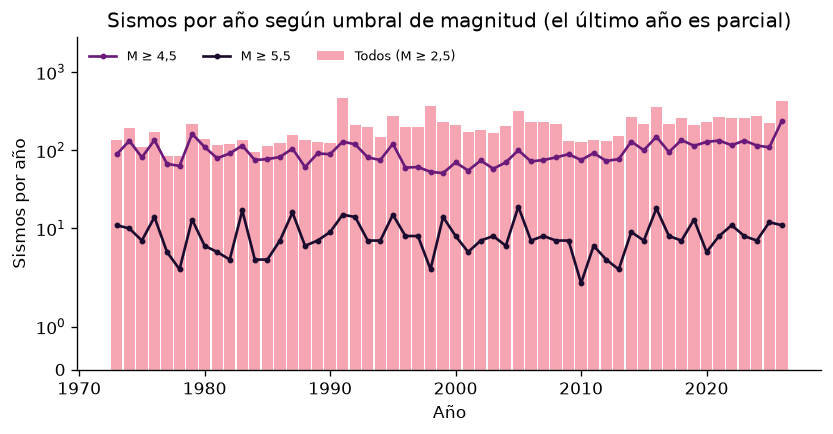

M ≥ 4,5 desde 1973: media 93.8 sismos/año, tendencia lineal +0.32 sismos/año por año


In [22]:
# Tasa anual desde 1973: si el umbral es completo, no debería haber tendencia instrumental
anios = np.arange(1973, int(ANIO_FIN) + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
todos = inst.anio.value_counts().reindex(anios, fill_value=0)
ax.bar(anios, todos, color="#f6a6b2", width=0.9, label=f"Todos (M ≥ {dec(MAG_MIN)})")
for umbral, color in [(MAG_COMPLETA, "#6a1b7a"), (5.5, "#1b0b2e")]:
    serie = inst[inst.mag >= umbral].anio.value_counts().reindex(anios, fill_value=0)
    ax.plot(anios, serie, color=color, lw=1.6, marker="o", ms=2.5, label=f"M ≥ {dec(umbral)}")
ax.set(yscale="symlog", xlabel="Año", ylabel="Sismos por año", ylim=(0, max(todos.max(), 1) * 6),
       title="Sismos por año según umbral de magnitud (el último año es parcial)")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
fig.savefig("completitud_tasa_anual.png", bbox_inches="tight", dpi=200); plt.show()

sub = inst[(inst.mag >= MAG_COMPLETA) & (inst.anio >= 1973) & (inst.anio < int(ANIO_FIN))]
por_anio = sub.anio.value_counts().reindex(anios[:-1], fill_value=0)
pend = np.polyfit(por_anio.index, por_anio.values, 1)[0]
print(f"M ≥ {dec(MAG_COMPLETA)} desde 1973: media {por_anio.mean():.1f} sismos/año, "
      f"tendencia lineal {pend:+.2f} sismos/año por año")

:::{figure} completitud_tasa_anual.png
:label: fig-tasa
:align: center
:alt: Sismos por año según el umbral de magnitud desde 1973
Sismos por año desde 1973 en el catálogo ampliado, para todos los eventos (barras) y para los de magnitud 4,5 o más y 5,5 o más (líneas), en escala simétrica logarítmica. El último año es parcial.
:::

Las curvas de los umbrales altos son estables, mientras que las barras de todos los eventos crecen con la instrumentación: el aumento del número de sismos registrados es un efecto de la red de estaciones y no de la actividad. Por eso para comparar épocas conviene filtrar por una magnitud completa.

## 13. Mapa de sismicidad con profundidad y víctimas

El mapa interactivo de la sección 9 no aparece en el PDF. La {numref}`Figura %s <fig-mapa-estatico>` resume el catálogo ampliado en un mapa estático: el tamaño del círculo indica la magnitud y el color la profundidad focal (la escala se satura en 200 km). Los sismos sin profundidad conocida se dibujan como anillos vacíos y no como superficiales, y los eventos grandes se dibujan primero para que no tapen a los pequeños. Se etiquetan los de mayor magnitud (en negro) y los que más víctimas causaron según NOAA (en rojo) (ver código en la versión web).

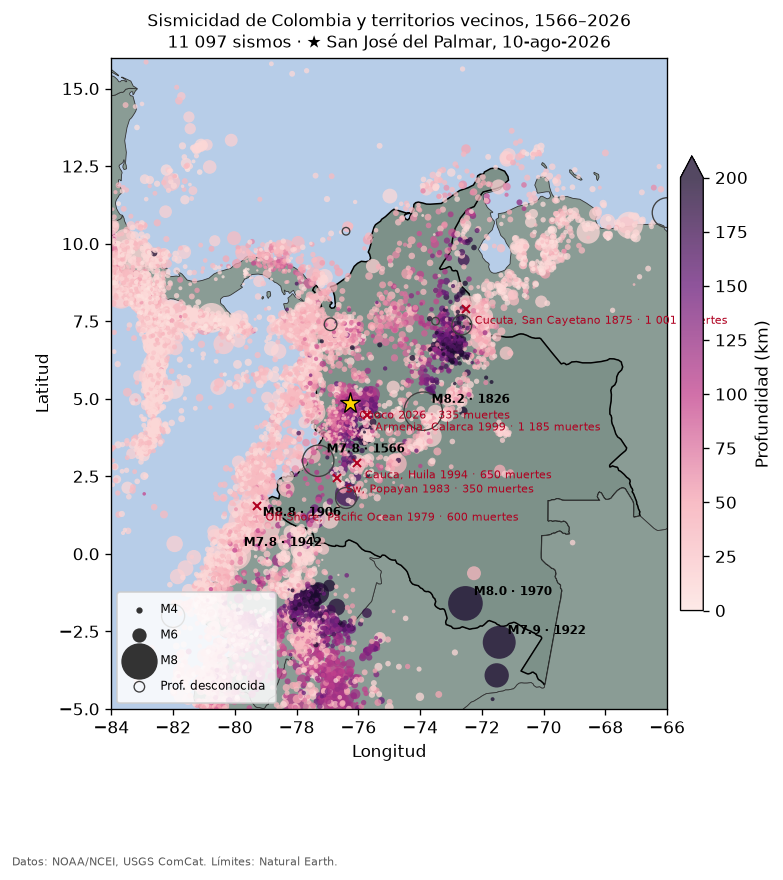

In [23]:
fig, ax = plt.subplots(figsize=(7.2, 8.2))
mapa_base(ax)
d_ord = cat.sort_values("mag", ascending=False)             # grandes debajo
con, sin = d_ord[d_ord.prof_km.notna()], d_ord[d_ord.prof_km.isna()]
sc = ax.scatter(con.lon, con.lat, s=tam(con.mag), c=con.prof_km, cmap=CMAP, norm=NORM, alpha=0.75,
                linewidths=0, rasterized=True)
ax.scatter(sin.lon, sin.lat, s=tam(sin.mag), facecolors="none", edgecolors="0.25", linewidths=0.8)
fig.colorbar(sc, ax=ax, shrink=0.6, pad=0.02, extend="max", label="Profundidad (km)")
leyenda_magnitud(ax)

for _, r in cat.nlargest(6, "mag").iterrows():                # etiquetas por magnitud
    ax.annotate(f"M{r.mag:.1f} · {r.anio}", (r.lon, r.lat), xytext=(5, 5), textcoords="offset points",
                fontsize=7, fontweight="bold")
if len(noaa) and noaa.muertes.notna().any():                   # etiquetas por impacto
    for _, r in noaa.dropna(subset=["muertes", "lat", "lon"]).nlargest(6, "muertes").iterrows():
        ax.plot(r.lon, r.lat, marker="x", color="#b00020", ms=5, mew=1.2)
        ax.annotate(f"{r.lugar} {int(r.anio_dec)} · {miles(r.muertes)} muertes", (r.lon, r.lat),
                    xytext=(5, -9), textcoords="offset points", fontsize=6.5, color="#b00020")
ax.plot(EVENTO_REF["lon"], EVENTO_REF["lat"], marker="*", ms=13, color="#ffd400", mec="k", mew=0.8)
ax.set_title(f"Sismicidad de Colombia y territorios vecinos, {cat.anio.min()}–{cat.anio.max()}\n"
             f"{miles(len(cat))} sismos · ★ {EVENTO_REF['nombre']}", fontsize=10)
fig.text(0.01, 0.005, f"{CREDITO} Límites: Natural Earth.", fontsize=6.5, color="0.35")
fig.savefig("mapa_estatico_sismicidad.png", bbox_inches="tight", dpi=200); plt.show()

:::{figure} mapa_estatico_sismicidad.png
:label: fig-mapa-estatico
:align: center
:alt: Mapa de sismicidad de Colombia y territorios vecinos coloreada por profundidad
Sismicidad de Colombia y territorios vecinos en el catálogo ampliado. El tamaño del círculo indica la magnitud y el color la profundidad focal (saturada en 200 km); los anillos vacíos son sismos sin profundidad conocida; las cruces rojas marcan los sismos con más víctimas según NOAA/NCEI y la estrella, el sismo de referencia de agosto de 2026.
:::

## 14. Cortes transversales

Un corte vertical muestra cómo se distribuye la sismicidad en profundidad. La {numref}`Figura %s <fig-cortes>` proyecta todo el cuadrante sobre un solo plano, Sur-Norte y Oeste-Este, hasta 200 km y con exageración vertical ×3, con la escala horizontal en kilómetros y los extremos rotulados. Hay dos advertencias de lectura: la exageración ×3 hace que una placa que buza 30° se vea a unos 60°, y al proyectar más de 2 000 km de país sobre un plano, estructuras que están a cientos de kilómetros entre sí aparecen una al lado de la otra (ver código en la versión web).

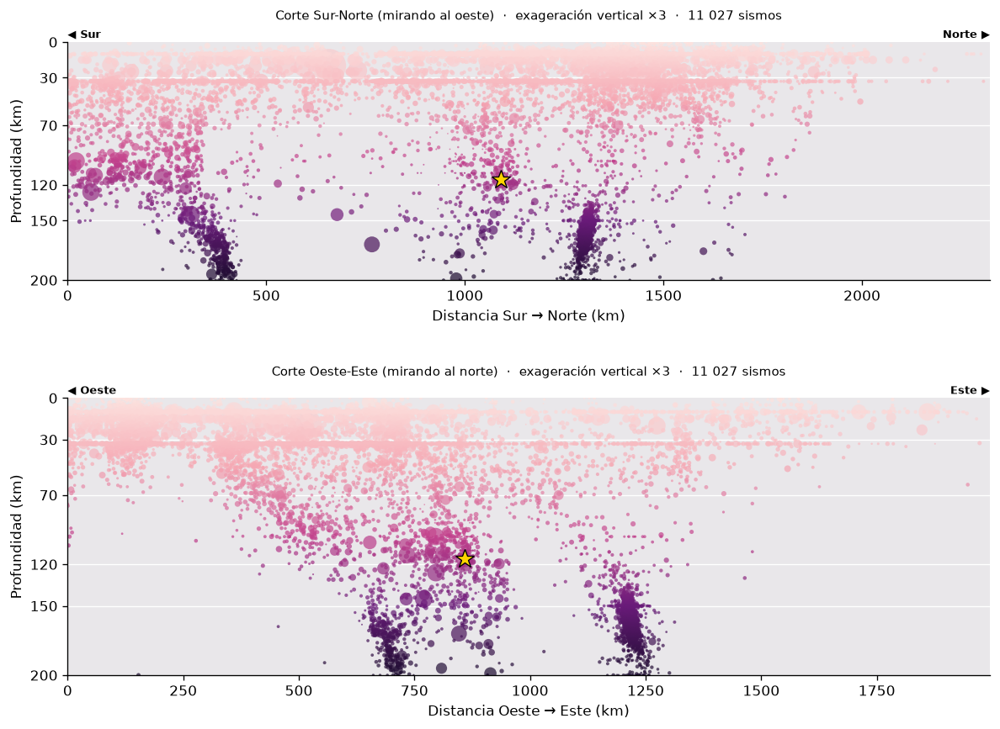

In [24]:
def corte(ax, df, eje="OE", banda=None, exag=EXAG_VERTICAL, lim=None, titulo=""):
    """Corte vertical. eje='OE' (mirando al norte) o 'SN' (mirando al oeste).
    banda=(min, max) limita la franja perpendicular al corte, en grados."""
    d = df[df.prof_km.notna() & (df.prof_km <= PROF_MAX)]
    if eje == "OE":
        if banda: d = d[d.lat.between(*banda)]
        h, origen, km, extremos = d.lon, BBOX["lon_min"], KM_LON, ("Oeste", "Este")
        lim = lim or (BBOX["lon_min"], BBOX["lon_max"]); ref = EVENTO_REF["lon"]
        en_banda = banda is None or banda[0] <= EVENTO_REF["lat"] <= banda[1]
    else:
        if banda: d = d[d.lon.between(*banda)]
        h, origen, km, extremos = d.lat, BBOX["lat_min"], KM_LAT, ("Sur", "Norte")
        lim = lim or (BBOX["lat_min"], BBOX["lat_max"]); ref = EVENTO_REF["lat"]
        en_banda = banda is None or banda[0] <= EVENTO_REF["lon"] <= banda[1]
    d = d.assign(h_km=(h - origen) * km).sort_values("mag", ascending=False)
    x0, x1 = [(v - origen) * km for v in lim]

    ax.set_facecolor("#e9e7ea")
    for z in (30, 70, 120, 150):
        ax.axhline(z, color="white", lw=0.8, zorder=0)
    ax.scatter(d.h_km, d.prof_km, s=tam(d.mag) * 0.6, c=d.prof_km, cmap=CMAP, norm=NORM,
               alpha=0.7, linewidths=0, rasterized=True)
    if en_banda and EVENTO_REF["prof_km"] <= PROF_MAX:
        ax.plot((ref - origen) * km, EVENTO_REF["prof_km"], marker="*", ms=14, color="#ffd400",
                mec="k", mew=0.8, zorder=5)
    ax.set_xlim(x0, x1); ax.set_ylim(PROF_MAX, 0); ax.set_aspect(exag)
    ax.set_yticks([0, 30, 70, 120, 150, PROF_MAX]); ax.set_ylabel("Profundidad (km)")
    ax.set_xlabel(f"Distancia {extremos[0]} → {extremos[1]} (km)")
    ax.annotate(f"◀ {extremos[0]}", (0, 1), xytext=(0, 3), xycoords="axes fraction",
                textcoords="offset points", fontsize=8, fontweight="bold")
    ax.annotate(f"{extremos[1]} ▶", (1, 1), xytext=(0, 3), xycoords="axes fraction",
                textcoords="offset points", fontsize=8, fontweight="bold", ha="right")
    ax.set_title(f"{titulo}  ·  exageración vertical ×{dec(exag)}  ·  {miles(len(d))} sismos", fontsize=9, pad=16)
    return d

fig, axs = plt.subplots(2, 1, figsize=(10, 7.6))
corte(axs[0], cat, "SN", titulo="Corte Sur-Norte (mirando al oeste)")
corte(axs[1], cat, "OE", titulo="Corte Oeste-Este (mirando al norte)")
fig.tight_layout(); fig.savefig("cortes_transversales.png", bbox_inches="tight", dpi=200); plt.show()

:::{figure} cortes_transversales.png
:label: fig-cortes
:align: center
:alt: Cortes verticales Sur-Norte y Oeste-Este de la sismicidad hasta 200 km
Cortes verticales de la sismicidad hasta 200 km de profundidad, con exageración vertical ×3. Arriba, corte Sur-Norte mirando al oeste; abajo, corte Oeste-Este mirando al norte. El color indica la profundidad, el tamaño la magnitud y la estrella el sismo de referencia de agosto de 2026.
:::

### 14.1 Cortes por franjas

En lugar de proyectar todo el país, se toman franjas de latitud. Así se separan los dos segmentos que el corte anterior superpone: el del **nido de Bucaramanga** y el del **occidente (Chocó–Eje Cafetero)**, donde ocurrió el sismo de agosto de 2026 (★). La {numref}`Figura %s <fig-franjas>` repite en el último panel la franja occidental **sin exageración vertical**, para mostrar la geometría real.

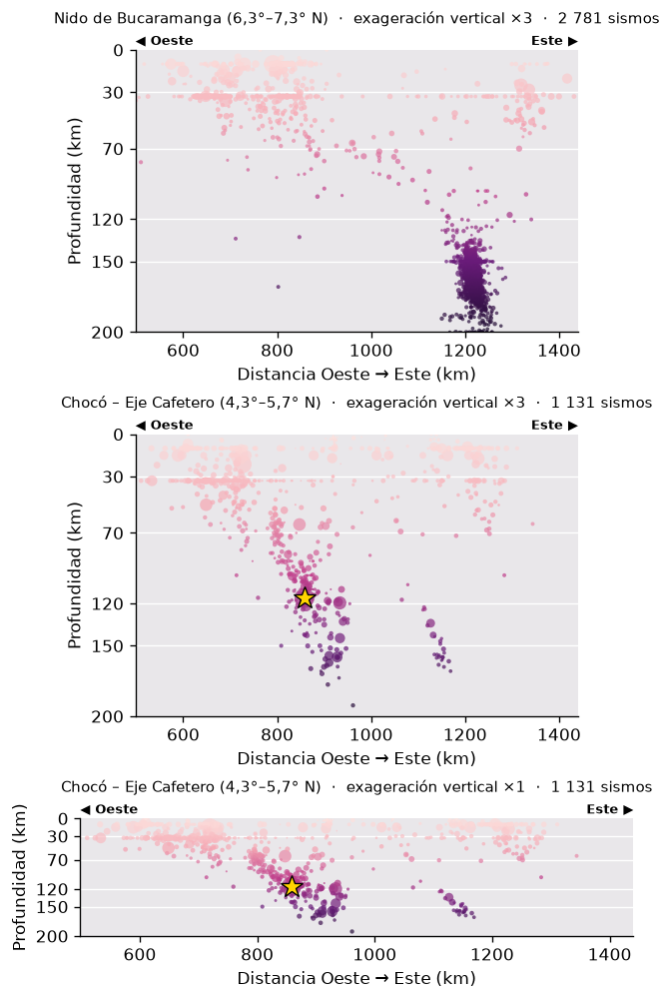

In [25]:
FRANJAS = {
    "Nido de Bucaramanga (6,3°–7,3° N)": (6.3, 7.3),
    "Chocó – Eje Cafetero (4,3°–5,7° N)": (4.3, 5.7),
}
LIM_LON = (-79.5, -71.0)

fig = plt.figure(figsize=(9, 9.6))
gs = fig.add_gridspec(3, 1, height_ratios=[EXAG_VERTICAL, EXAG_VERTICAL, 1.25], hspace=0.45)
for i, (nombre, banda) in enumerate(FRANJAS.items()):
    corte(fig.add_subplot(gs[i]), cat, "OE", banda=banda, lim=LIM_LON, titulo=nombre)
ultima = list(FRANJAS.items())[-1]
corte(fig.add_subplot(gs[2]), cat, "OE", banda=ultima[1], lim=LIM_LON, exag=1, titulo=ultima[0])
fig.savefig("cortes_franjas.png", bbox_inches="tight", dpi=200); plt.show()

:::{figure} cortes_franjas.png
:label: fig-franjas
:align: center
:alt: Cortes Oeste-Este por franjas de latitud con y sin exageración vertical
Cortes Oeste-Este por franjas de latitud. Arriba, nido de Bucaramanga (6,3° a 7,3° N); en medio, Chocó–Eje Cafetero (4,3° a 5,7° N), ambos con exageración vertical ×3; abajo, la misma franja occidental sin exageración (×1). La estrella marca el sismo de referencia de agosto de 2026.
:::

## 15. Vista 3D interactiva

La vista 3D permite girar y acercar la nube de sismos para ver cómo cambia la profundidad con la posición. Se limita a magnitud 4 o más y a 200 km para que sea liviana; el eje vertical conserva la exageración de los cortes y el borde de Colombia se dibuja sobre la superficie. Pasa el cursor sobre un punto para ver su magnitud, fecha y profundidad. La vista no se reproduce en el PDF (ver código en la versión web).

In [26]:
import plotly.graph_objects as go

d3 = cat[cat.prof_km.notna() & (cat.prof_km <= PROF_MAX) & (cat.mag >= 4.0)]
escala = [[i / 4, c] for i, c in enumerate(["#fde3df", "#f6a6b2", "#c2408c", "#6a1b7a", "#1b0b2e"])]

fig3d = go.Figure()
for p in colombia:                                              # borde de Colombia
    fig3d.add_trace(go.Scatter3d(x=list(p[:, 0]), y=list(p[:, 1]), z=[0] * len(p), mode="lines",
                                 line=dict(color="black", width=3), hoverinfo="skip", showlegend=False))
fig3d.add_trace(go.Scatter3d(
    x=d3.lon, y=d3.lat, z=-d3.prof_km, mode="markers", showlegend=False,
    marker=dict(size=np.clip((d3.mag - 3) * 1.8, 1.5, 12), color=d3.prof_km, colorscale=escala, cmin=0,
                cmax=PROF_MAX, opacity=0.75, line=dict(width=0), colorbar=dict(title="Prof. (km)", len=0.6)),
    text=[f"M{m:.1f} · {f}<br>{p:.0f} km" for m, f, p in zip(d3.mag, d3.fecha, d3.prof_km)], hoverinfo="text"))
fig3d.add_trace(go.Scatter3d(x=[EVENTO_REF["lon"]], y=[EVENTO_REF["lat"]], z=[-EVENTO_REF["prof_km"]],
    mode="markers+text", text=["★ 10-ago-2026"], textposition="top center", showlegend=False,
    marker=dict(size=7, color="#ffd400", symbol="diamond", line=dict(color="black", width=2))))

dx = (BBOX["lon_max"] - BBOX["lon_min"]) * KM_LON
dy = (BBOX["lat_max"] - BBOX["lat_min"]) * KM_LAT
fig3d.update_layout(
    title=f"Sismicidad M ≥ 4 hasta {PROF_MAX} km · exageración vertical ×{dec(EXAG_VERTICAL)}",
    height=620, margin=dict(l=0, r=0, t=40, b=0),
    scene=dict(xaxis_title="Longitud", yaxis_title="Latitud", zaxis_title="Profundidad (km)",
               xaxis=dict(range=[BBOX["lon_min"], BBOX["lon_max"]]),
               yaxis=dict(range=[BBOX["lat_min"], BBOX["lat_max"]]), zaxis=dict(range=[-PROF_MAX, 0]),
               aspectmode="manual", aspectratio=dict(x=1, y=dy / dx, z=PROF_MAX * EXAG_VERTICAL / dx),
               camera=dict(eye=dict(x=-1.3, y=-1.6, z=0.9))))
fig3d.show()

## 16. Resumen del Análisis y Próximos Pasos

Este cuaderno realizó un análisis exploratorio de la sismicidad de Colombia usando únicamente datos públicos y herramientas de código abierto. Los resultados ilustran el carácter **multiamenaza** del territorio y la riqueza de información disponible para análisis de riesgo sísmico.

El resumen numérico del catálogo se imprime en la celda siguiente (ver código en la versión web).

In [27]:
print('=' * 60)
print('  RESUMEN — SISMICIDAD DE COLOMBIA 2000–2026')
print('=' * 60)
print(f'  Total de eventos M ≥ 3.0:     {len(df):,}')
print(f'  Magnitud máxima registrada:   M {df["magnitud"].max():.1f}')
print(f'  Magnitud media:               M {df["magnitud"].mean():.2f}')
print(f'  Profundidad media:            {df["profundidad_km"].mean():.1f} km')
print(f'  Eventos superficiales (≤70):  {(df["profundidad_km"]<=70).sum():,} ({(df["profundidad_km"]<=70).mean()*100:.1f}%)')
print(f"  Período de análisis:          2000 – {df['tiempo'].max():%Y-%m-%d}")
print(f"  Magnitud de completitud (Mc): M {gr['mc']:.1f}")
print(f"  b-value (máx. verosimilitud): {gr['b_ml']:.2f} ± {gr['b_se']:.2f}")
print('=' * 60)
print()
print('Archivos generados:')
print('  📊 sismicidad_temporal.png')
print('  📊 gutenberg_richter.png')
print('  📊 profundidad_focal.png')
print('  📊 variacion_estacional.png')
print('  🗺️  mapa_sismicidad_colombia.html')


  RESUMEN — SISMICIDAD DE COLOMBIA 2000–2026
  Total de eventos M ≥ 3.0:     4,769
  Magnitud máxima registrada:   M 7.8
  Magnitud media:               M 4.43
  Profundidad media:            77.6 km
  Eventos superficiales (≤70):  2,694 (56.5%)
  Período de análisis:          2000 – 2026-11-13
  Magnitud de completitud (Mc): M 4.5
  b-value (máx. verosimilitud): 1.07 ± 0.02

Archivos generados:
  📊 sismicidad_temporal.png
  📊 gutenberg_richter.png
  📊 profundidad_focal.png
  📊 variacion_estacional.png
  🗺️  mapa_sismicidad_colombia.html


### 16.1 Lectura y límites

**Qué se puede afirmar.** El crecimiento del número de sismos registrados es un efecto de instrumentación: desaparece al filtrar por una magnitud completa. La sismicidad intermedia dibuja placas que se hunden hacia el este, con dos segmentos distintos, y el sismo de agosto de 2026 se ubica dentro del segmento occidental, a profundidad intermedia.

**Qué no.** Este cuaderno describe **amenaza**, no riesgo: no incluye exposición ni vulnerabilidad. La sismicidad cortical (la que más daño suele causar) queda mal representada en cortes a escala de país.

**Límites de los datos.**

- El catálogo del USGS es completo para la región solo desde magnitudes cercanas a 4,5; no reproduce los conteos del catálogo del Servicio Geológico Colombiano.
- Mezcla tipos de magnitud (Mw, mb, Ml, Ms) sin homogeneizar. El Catálogo Sísmico Integrado del SGC sí lo hace (Montejo et al., 2023).
- Muchas profundidades antiguas son valores fijos asignados por la agencia (10, 33, 35 km) y las incertidumbres en profundidad son mayores que las horizontales; la exageración vertical las amplifica.
- Las magnitudes históricas se derivan de intensidades y los eventos anteriores a 1900 dependen de lo que quedó documentado.
- La conversión de grados a kilómetros usa una aproximación plana con la latitud media del cuadrante.

### 16.2 Próximos pasos y extensiones

El cuaderno puede extenderse de varias maneras. La {numref}`Tabla %s <tbl-extensiones>` resume algunas ideas para contribuciones a la plataforma.

:::{table} Extensiones propuestas del cuaderno.
:label: tbl-extensiones

| Extensión | Descripción | Complejidad |
|---|---|---|
| **Microzonificación** | Cruzar catálogo sísmico con datos de suelo y NSR-10 para análisis local | Media |
| **PSHA simplificado** | Implementar curvas de peligro sísmico con OpenQuake para ciudades principales | Alta |
| **Enjambres sísmicos** | Detección automática de enjambres con algoritmos de clustering (DBSCAN) | Media |
| **Relación lluvia-sismo** | Correlación entre precipitación intensa y sismicidad inducida | Media |
| **Alerta temprana** | Simular un sistema de detección en tiempo real con la API del USGS | Alta |
| **ML para clasificación** | Clasificar tipos de sismo con aprendizaje automático | Alta |

PSHA, análisis probabilista de amenaza sísmica; NSR-10, Reglamento Colombiano de Construcción Sismo Resistente.
:::

## 17. Referencias

1. USGS Earthquake Hazards Program. *FDSN Event Web Service*. https://earthquake.usgs.gov/fdsnws/event/1/
2. Servicio Geológico Colombiano. *Catálogo de Sismicidad de Colombia*. https://www.sgc.gov.co
3. Aki, K. (1965). Maximum likelihood estimate of *b* in the formula log N = a − bM and its confidence limits. *Bulletin of the Earthquake Research Institute*, 43, 237–239. Utsu, T. (1966). A statistical significance test of the difference in b-value between two earthquake groups. *Journal of Physics of the Earth*, 14, 37–40.
4. Gutenberg, B. & Richter, C.F. (1944). Frequency of earthquakes in California. *Bulletin of the Seismological Society of America*, 34(4), 185–188.
5. UNGRD (2019). *Atlas de Riesgo de Colombia: revelando los desastres latentes*. Unidad Nacional para la Gestión del Riesgo de Desastres.
6. Montejo, J., Arcila, M. y Zornosa, D. (2023). Catálogo Sísmico Integrado para Colombia. *Boletín Geológico*, 50(1). https://doi.org/10.32685/0120-1425/bol.geol.50.1.2023.665
7. NOAA National Centers for Environmental Information. *Global Significant Earthquake Database*. https://doi.org/10.7289/V5TD9V7K
8. Wiemer, S. y Wyss, M. (2000). Minimum magnitude of completeness in earthquake catalogs. *Bulletin of the Seismological Society of America*, 90(4), 859–869.
9. UNDRR-ROAS (2024). *Inteligencia artificial para la reducción del riesgo de desastres en América Latina y el Caribe*.

*Plataforma de Análisis de Riesgos — Subdirección para el Conocimiento del Riesgo · UNGRD*  
*Licencia: Creative Commons BY 4.0 · Código: MIT License*